# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import BDCI2020Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 145981


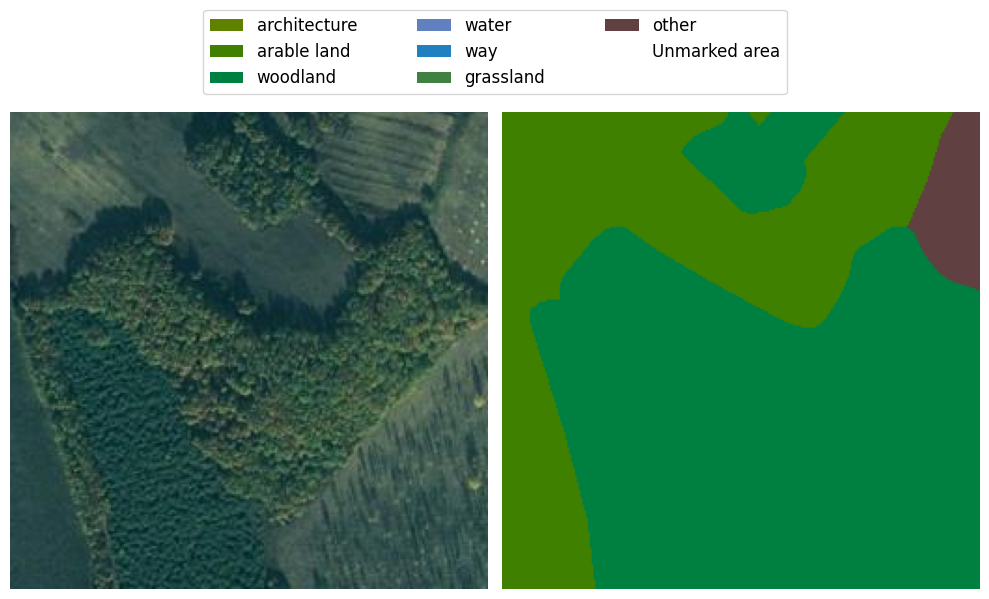

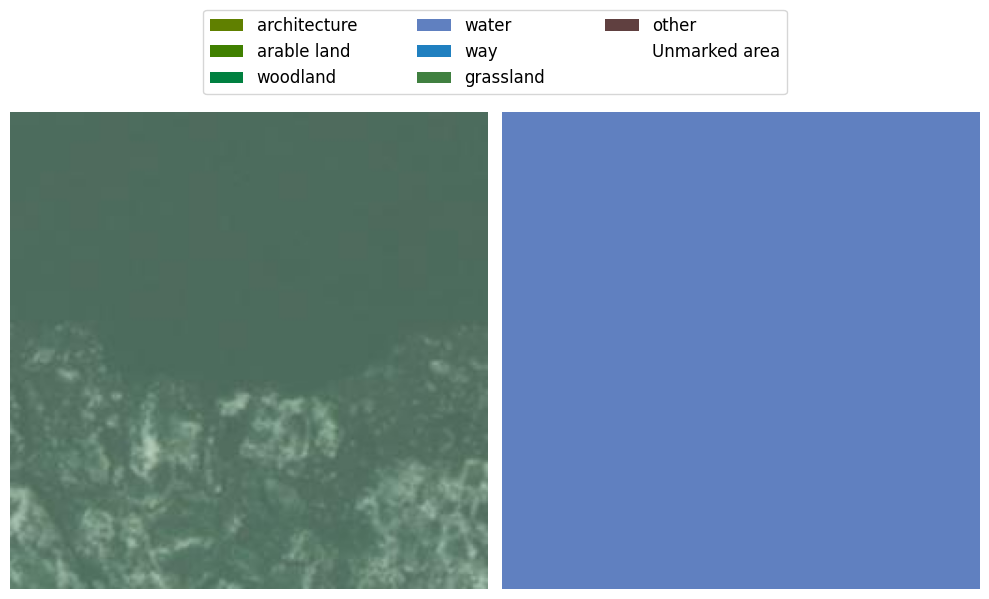

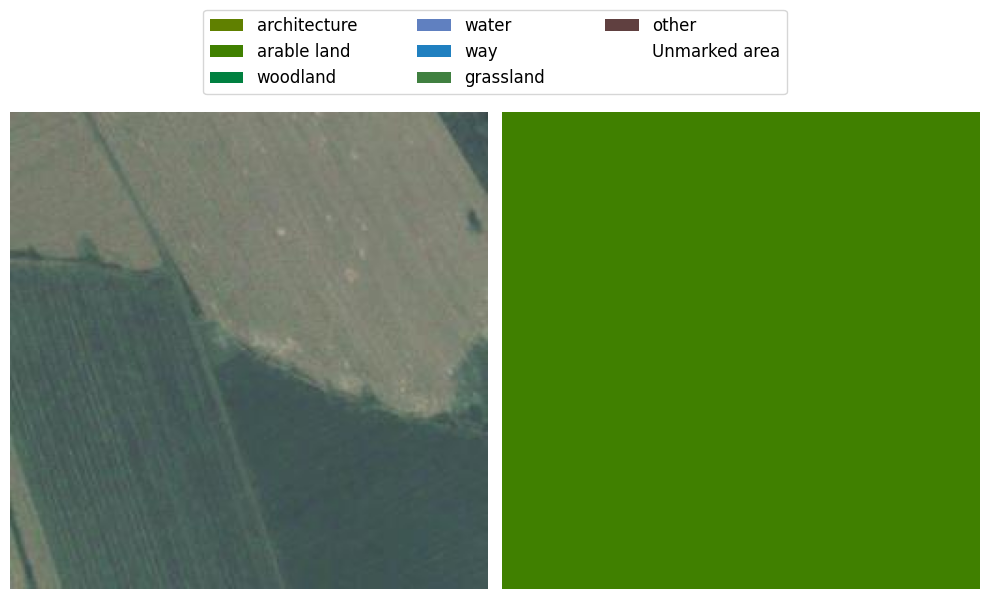

In [ ]:
dataset_config = {
    "data_dir": "./data/BDCI2020/train/"
}
dataset = BDCI2020Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(350);
dataset.show_image(500);

In [11]:
dataset.data_distribution_table()

,Number of pixels
architecture,2.207374e+08
arable land,4.955696e+09
woodland,1.704444e+09
water,1.578705e+09
way,3.781896e+07
grassland,1.910768e+08
other,7.615487e+08
Unmarked area,0.000000e+00


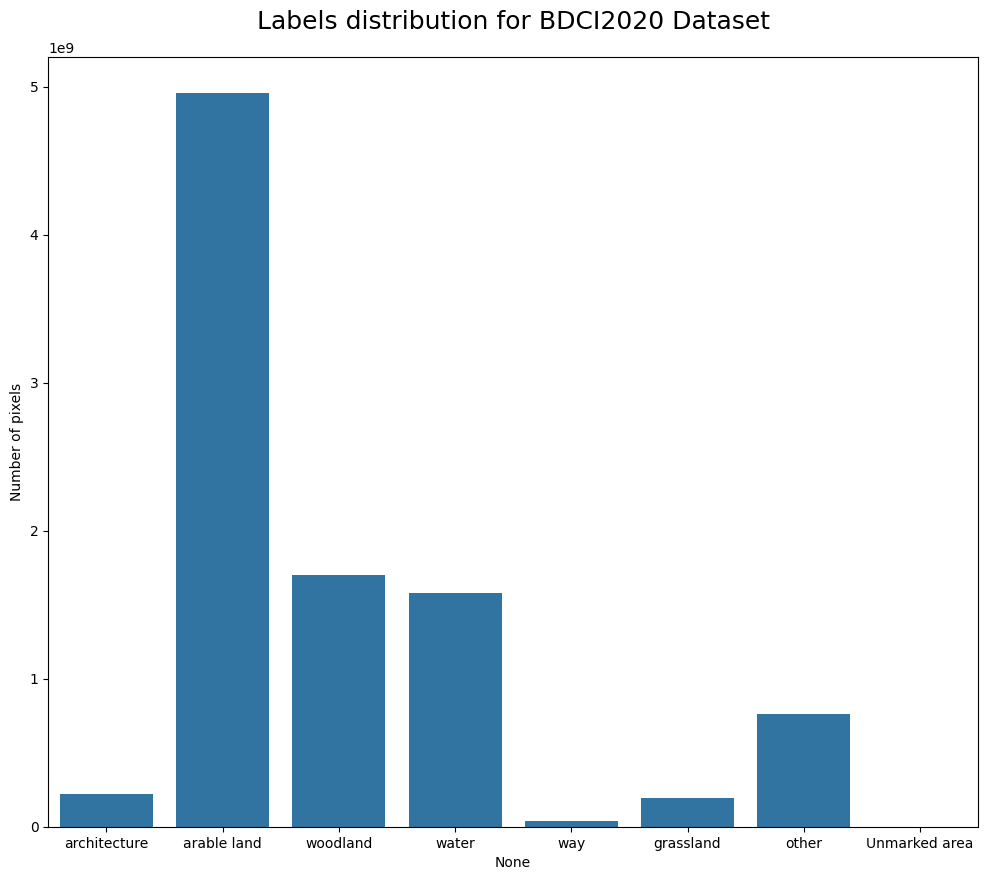

In [12]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/BDCI2020/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = BDCI2020Dataset(train_dataset_config)
len(train_dataset)

145981

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/BDCI2020/"
model_config = {
    "num_classes": 8, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-30 06:43:18,085 INFO Starting training.
training: 100%|██████████| 18248/18248 [27:44<00:00, 10.96it/s]
2025-05-30 07:11:02,543 INFO epoch: 1, time: 1664, loss:  0.15635
testing on train set: 100%|██████████| 18248/18248 [11:30<00:00, 26.41it/s]
2025-05-30 07:22:35,552 INFO IOU:0.7492438864200271, IOU mean:0.4024353194853217, IOU per Class:[0.33774152 0.80915646 0.74327779 0.83626178 0.         0.
 0.49304502 0.        ]
training: 100%|██████████| 18248/18248 [28:12<00:00, 10.78it/s]
2025-05-30 07:50:48,436 INFO epoch: 2, time: 1693, loss:  0.12305
testing on train set: 100%|██████████| 18248/18248 [12:08<00:00, 25.05it/s]
2025-05-30 08:02:57,056 INFO IOU:0.8015534799222092, IOU mean:0.47076415225058865, IOU per Class:[0.70948572 0.85685556 0.82733282 0.8562497  0.         0.
 0.51618942 0.        ]
training: 100%|██████████| 18248/18248 [27:41<00:00, 10.98it/s]
2025-05-30 08:30:38,578 INFO epoch: 3, time: 1661, loss:  0.11637
testing on train set: 100%|██████████| 18248/18248 

## Predictions

2025-05-30 13:17:20,883 INFO Loading checkpoint /home/dragik/data/FAIR_EO/BDCI2020/checkpoint.pth.tar
2025-05-30 13:17:21,356 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/BDCI2020/checkpoint.pth.tar at epoch 11


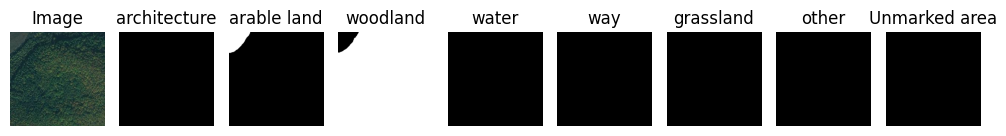

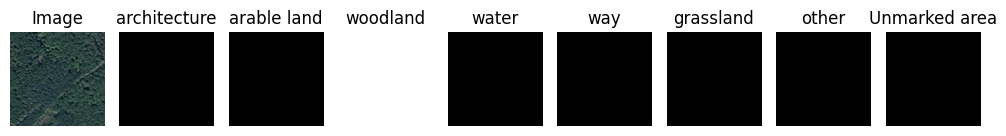

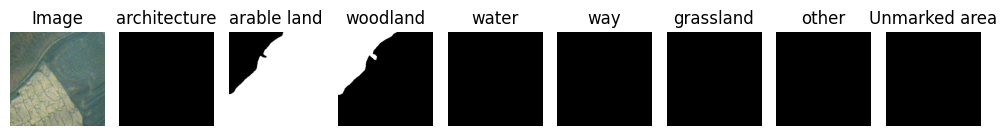

In [ ]:
model_path = "./data/BDCI2020/checkpoint.pth.tar"
labels = ["architecture","arable land","woodland","water","way","grassland","other","Unmarked area"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('./data/BDCI2020/test/images/A145986.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BDCI2020/test/images/A146009.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/BDCI2020/test/images/A146035.jpg')
fig = model.predict_masks(image, labels, transform)